# Fig. 5a-c and Extended Data Fig. 9: Visium HD mouse brain

Fig. 5a-c is a showcase of EnrichMap (null) (`n_neighbors=50`) on the 16-um bins of `02_visiumhd_platform`: a Leiden
clusters, b EnrichMap (null) maps, c Spink8 and Penk. Extended Data Fig. 9: a AUCell, GSVA, ssGSEA, Z score, Scanpy (stored by
that notebook) and GSDensity, b Lefty1 and Adora2a, c the pyramidal reference and the benchmark summary.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN
from sklearn.metrics import average_precision_score, roc_auc_score

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}

In [6]:
from helpers import (
    set_box_ratio,
    visiumhd_marker_stretch,
    visiumhd_plot_summary,
    visiumhd_readouts,
    visiumhd_ring_distance,
)

In [7]:
# 1. Load the stored Visium HD object (02 cell 29) and the signatures (02 cell 9)
adata = sc.read_h5ad(processed_data + "visiumhd_pyramidal_layer_scores.h5ad")
coords = np.asarray(adata.obsm["spatial"], dtype=float)

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open(project_dir + f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)

with open(project_dir + f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_striatum = pickle.load(f)

pyramidal_layer_geneset = signature_dict_pyramidal[f"{cell_type_1}_top20"]
striatum_geneset = signature_dict_striatum[f"{cell_type_2}_top50"]

signature_dict = {cell_type_1: pyramidal_layer_geneset, cell_type_2: striatum_geneset}
region_label = {cell_type_1: "Pyramidal layer", cell_type_2: "Striatum"}
for ct, genes in signature_dict.items():
    print(f"{ct}: {sum(g in adata.var_names for g in genes)}/{len(genes)} genes in the object")

leiden = adata.obs["leiden"].astype(str).values
leiden_levels = sorted(np.unique(leiden), key=int)

# bin spacing in plotted (lowres pixel) units = 16 um
bin_px = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
bin_um = 16.0

Pyramidal_layer: 13/20 genes in the object
Striatum: 40/50 genes in the object


In [8]:
# 2. EnrichMap (null) (02 cell 15: n_neighbors=50, no batch_key); the Sup. Fig. 11c readouts use p_empirical
variants = {"null": dict(compute_q_vals=True)}

for name, kwargs in variants.items():
    em.tl.score(
        adata,
        gene_set={f"{ct}_{name}": genes for ct, genes in signature_dict.items()},
        n_neighbors=50,
        **kwargs,
    )

  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_null: 13/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_null: 13/20 genes found:  50%|█████     | 1/2 [00:00<00:00,  5.41it/s]

Scoring Striatum_null: 40/50 genes found:  50%|█████     | 1/2 [00:00<00:00,  5.41it/s]       

Scoring Striatum_null: 40/50 genes found: 100%|██████████| 2/2 [00:00<00:00,  4.88it/s]

Scoring Striatum_null: 40/50 genes found: 100%|██████████| 2/2 [00:00<00:00,  4.94it/s]

In [9]:
# 3. Comparators as stored by 02 (cells 16-24, not re-run) and GSDensity relevance (R package, all bins)
gsd_positive = {}
for ct in signature_dict:
    gsd = pd.read_csv(working_dir + f"data/gsd_cache/visiumhd/{ct}.csv", index_col=0).reindex(adata.obs_names)
    # relevance x n bins (mean 1): relevance sums to 1 over the bins, so this is a constant rescaling
    adata.obs[f"{ct}_gsdensity_score"] = gsd["relevance_scaled"].values
    # native antimode calls of GSDensity
    gsd_positive[ct] = (gsd["label"] == "positive").values

# score column of each method
method_keys = {
    "EnrichMap (null)": "{ct}_null_score",
    "AUCell": "{ct}_aucell_score",
    "GSVA": "{ct}_gsva_score",
    "ssGSEA": "{ct}_ssgsea_score",
    "Z score": "{ct}_z_score",
    "Scanpy": "{ct}_scanpy_score",
    "GSDensity": "{ct}_gsdensity_score",
}
methods = list(method_keys)
values = {(ct, m): adata.obs[k.format(ct=ct)].values.astype(float) for ct in signature_dict for m, k in method_keys.items()}

marker_genes = ["Spink8", "Penk", "Lefty1", "Adora2a", "Prox1"]
expr = sc.get.obs_df(adata, keys=marker_genes)

# for ct in signature_dict:
#     for m in ["EnrichMap (null model)", "EnrichMap (smoothing-only)", "GSDensity"]:
#         s = values[(ct, m)]
#         print(f"{ct:<16} {m:<27} range {s.min():9.4g} to {s.max():9.4g}; bins > 0 = {100 * (s > 0).mean():5.1f}%")

Visium HD has no region annotation, so regions are taken from the Leiden clusters of Fig. 5a as references for AUROC
and AUPRC: for the striatum, the Adora2a+ stretch of the main connected part of cluster 6 and, for the pyramidal layer, the
Lefty1+ band of cluster 7. Cluster 7 holds two
separate bands, split by spatial connectivity; the dentate band is the one with the higher Prox1. The annotated Visium
slide labels only the Lefty1+ arc as the pyramidal layer, so the reference is the stretch of the other band where Lefty1,
averaged over the 25 nearest bins of the band, exceeds its maximum in the dentate band. The striatal band uses the same rule, with cluster 7 as the negative control. The references come
from the same expression data, and Lefty1 and Adora2a are themselves signature genes, so they are not independent ground truth.

In [10]:
# 4. Readouts per map against the Leiden-cluster region references
leiden_proxy = {cell_type_1: "7", cell_type_2: "6"}
ring_edges = [0, 80, 160, 320, 640]  # distance bands outside each region (um)
dbscan_eps_bins = 1.5  # DBSCAN radius (bins) that splits cluster 7 into its bands

sq.gr.spatial_neighbors(adata, n_neighs=6, coord_type="generic", key_added="spatial")
W6 = adata.obsp["spatial_connectivities"]

# cluster 7 holds the pyramidal and the dentate band: split them by spatial connectivity; dentate has the higher Prox1
m7 = leiden == leiden_proxy[cell_type_1]
component = np.full(adata.n_obs, -2)
component[m7] = DBSCAN(eps=dbscan_eps_bins * bin_px, min_samples=3).fit_predict(coords[m7])
bands = [c for c in pd.Series(component[m7]).value_counts().index if c >= 0][:2]
pyramidal_band = min(bands, key=lambda c: expr["Prox1"].values[component == c].mean())
dentate_band = max(bands, key=lambda c: expr["Prox1"].values[component == c].mean())

# the pyramidal layer as annotated on Visium is the Lefty1+ stretch of that band; the dentate band is the negative control
lefty1_band = visiumhd_marker_stretch(
    component == pyramidal_band, component == dentate_band, expr["Lefty1"].values, coords, dbscan_eps_bins * bin_px
)

# the striatal reference, by the same rule: the Adora2a+ stretch of the main connected part of cluster 6, with cluster 7 as
# the negative control (scattered bins and the ventral tail of cluster 6 are left out)
m6 = leiden == leiden_proxy[cell_type_2]
component_6 = np.full(adata.n_obs, -2)
component_6[m6] = DBSCAN(eps=dbscan_eps_bins * bin_px, min_samples=3).fit_predict(coords[m6])
main_6 = pd.Series(component_6[m6][component_6[m6] >= 0]).value_counts().index[0]
adora2a_band = visiumhd_marker_stretch(
    component_6 == main_6, m7, expr["Adora2a"].values, coords, dbscan_eps_bins * bin_px
)

# region references: (signature, mask, description)
proxies = {
    "Pyramidal layer": (cell_type_1, lefty1_band, f"Lefty1+ band of Leiden cluster {leiden_proxy[cell_type_1]}"),
    "Striatum": (cell_type_2, adora2a_band, f"Adora2a+ band of Leiden cluster {leiden_proxy[cell_type_2]}"),
}

summary_rows = []
region_mask = {}
for proxy, (ct, in_region, desc) in proxies.items():
    dist = visiumhd_ring_distance(in_region, coords, bin_px, bin_um)
    region_mask[proxy] = in_region
    for m in methods:
        s = values[(ct, m)]
        row = {"region": proxy, "signature": ct, "proxy": desc, "n region bins": int(in_region.sum()),
               "prevalence": float(in_region.mean()), "method": m}
        row.update(visiumhd_readouts(s, in_region, dist, m, ct, adata, gsd_positive, W6, ring_edges))
        summary_rows.append(row)
metrics = pd.DataFrame(summary_rows)

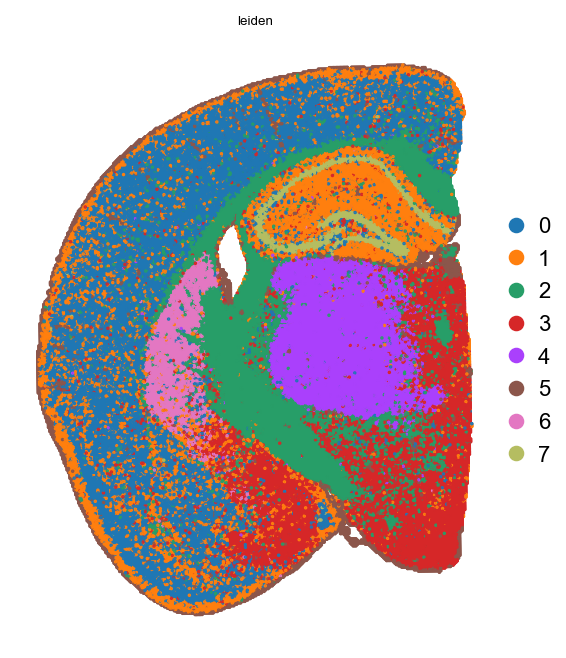

In [11]:
# 7. Fig. 5a: unbiased Leiden clusters (02 cell 14)
sq.pl.spatial_scatter(
    adata,
    color="leiden",
    save="Fig5a_visiumhd_leiden_clusters.pdf",
    shape=None
)
clusters = adata.obs[["leiden"]].copy()
clusters.insert(0, "y", coords[:, 1])
clusters.insert(0, "x", coords[:, 0])
clusters.to_csv(source_dir + "Fig5a_visiumhd_leiden_clusters.csv")

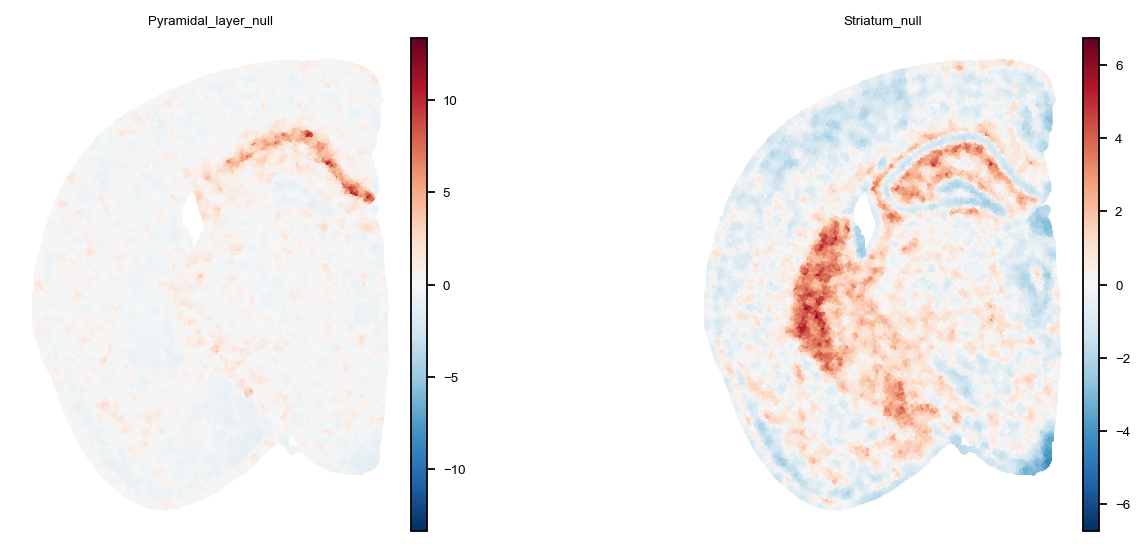

In [12]:
# 8. Fig. 5b: EnrichMap (null) for both regions (02 cell 26), centred and uncentred
methods_5b = ["EnrichMap (null)"]
keys = [method_keys[m].format(ct=ct) for ct in signature_dict for m in methods_5b]
em.pl.spatial_enrichmap(
    adata,
    score_key=keys,
    ncols=3,
    save=f"Fig5b_visiumhd.pdf",
    shape=None
)
maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "Fig5b_visiumhd.csv")

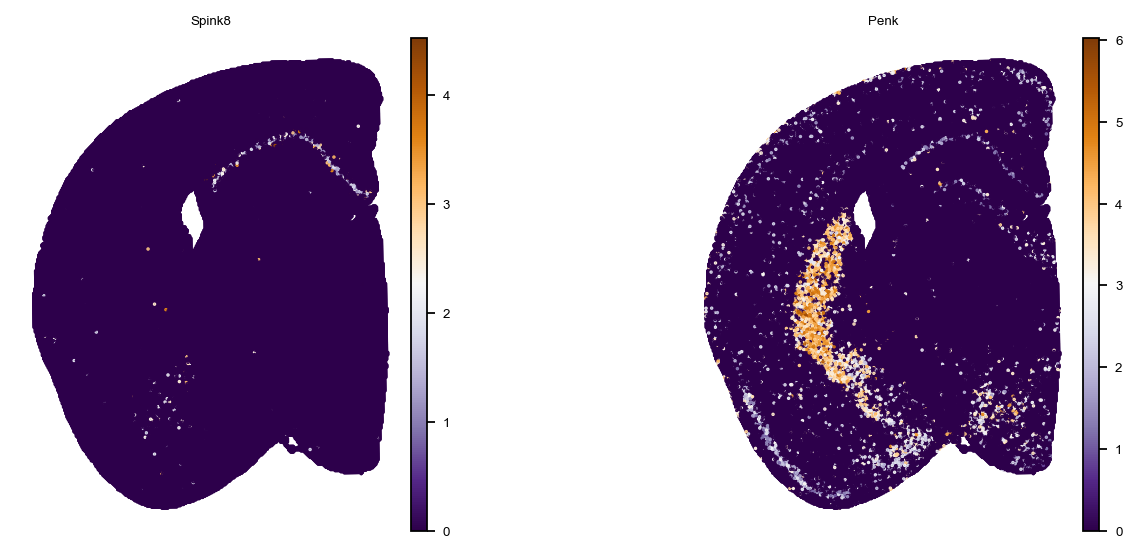

In [13]:
# 9. Fig. 5c: Spink8 and Penk expression (log-normalised)
sq.pl.spatial_scatter(
    adata,
    color=["Spink8", "Penk"],
    ncols=2,
    cmap="PuOr_r",
    save=f"Fig5c_visiumhd_spink8_penk.pdf",
    shape=None
)
genes = expr[["Spink8", "Penk"]].copy()
genes.insert(0, "y", coords[:, 1])
genes.insert(0, "x", coords[:, 0])
genes.to_csv(source_dir + "Fig5c_visiumhd_spink8_penk.csv")

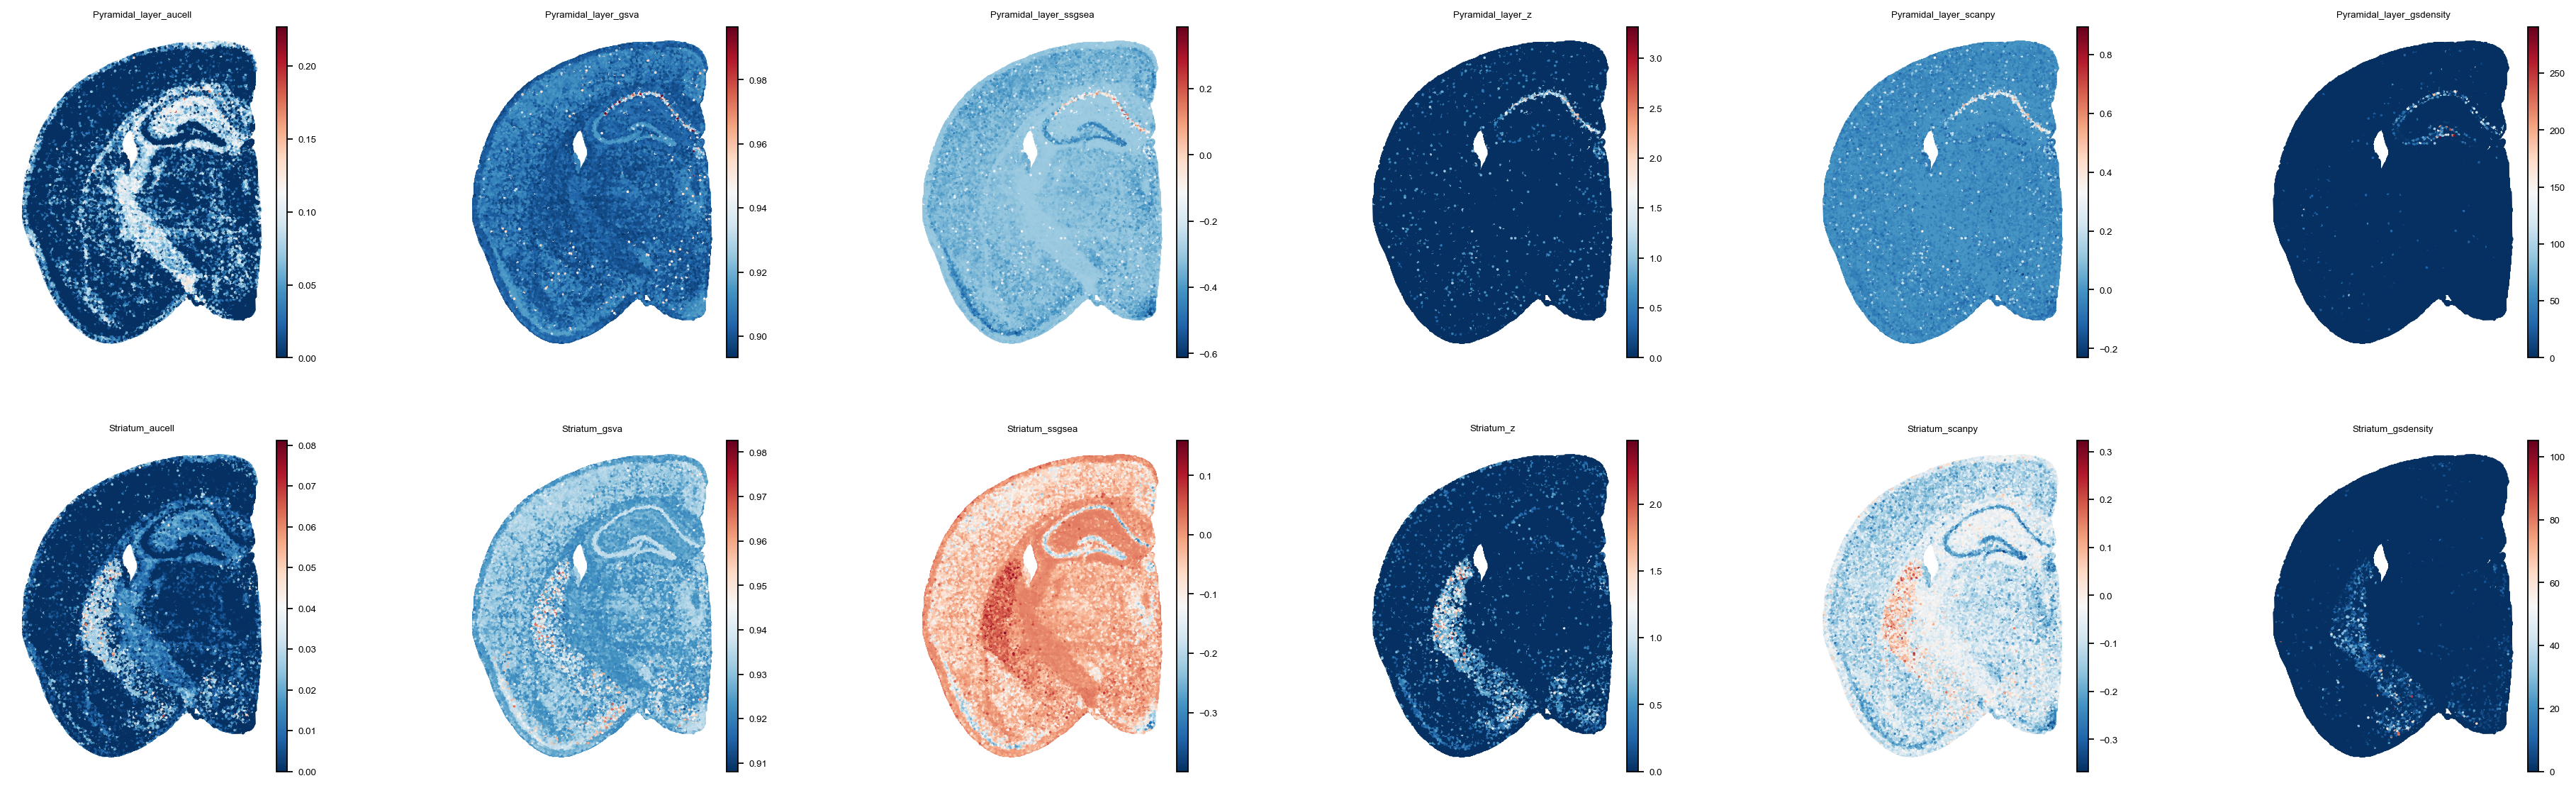

In [14]:
# 10. Extended Data Fig. 9a: the comparators and GSDensity for both regions (02 cell 26), from minimum to maximum
keys = [method_keys[m].format(ct=ct) for ct in signature_dict for m in methods if m != "EnrichMap (null)"]
em.pl.spatial_enrichmap(
    adata,
    score_key=keys,
    vcenter=None,
    ncols=6,
    save=f"ExtendedDataFig9a_visiumhd_methods.pdf",
    shape=None
)
maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "ExtendedDataFig9a_visiumhd_methods.csv")


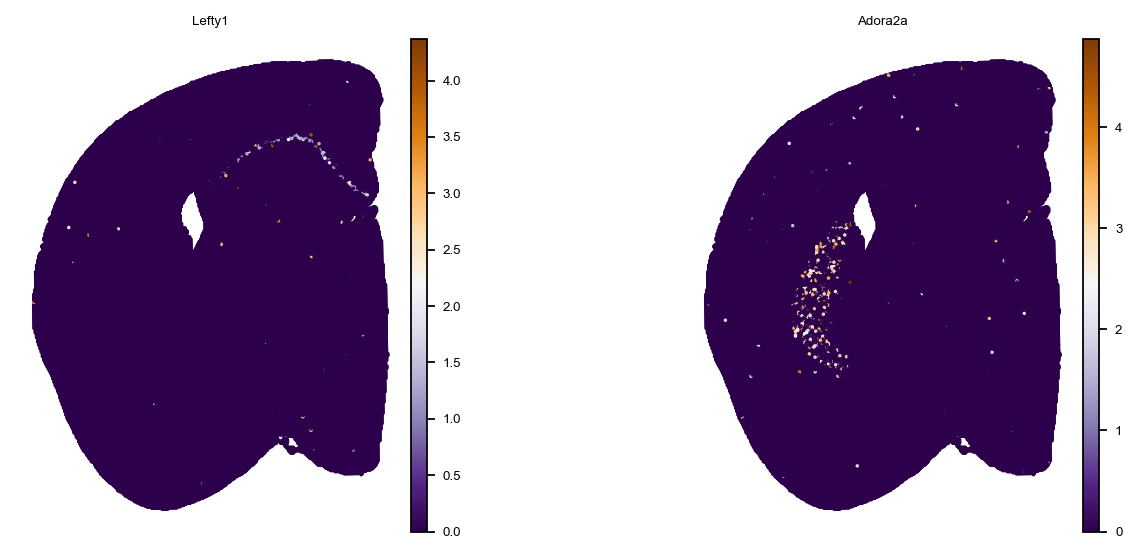

In [15]:
# 11. Extended Data Fig. 9b: Lefty1 and Adora2a expression (log-normalised)
sq.pl.spatial_scatter(
    adata,
    color=["Lefty1", "Adora2a"],
    ncols=2,
    cmap="PuOr_r",
    save=f"ExtendedDataFig9b_visiumhd_lefty1_adora2a.pdf",
    shape=None
)
genes = expr[["Lefty1", "Adora2a"]].copy()
genes.insert(0, "y", coords[:, 1])
genes.insert(0, "x", coords[:, 0])
genes.to_csv(source_dir + "ExtendedDataFig9b_visiumhd_lefty1_adora2a.csv")

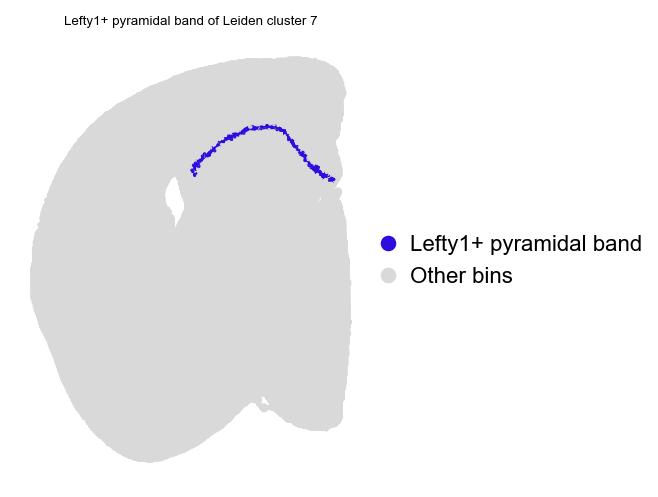

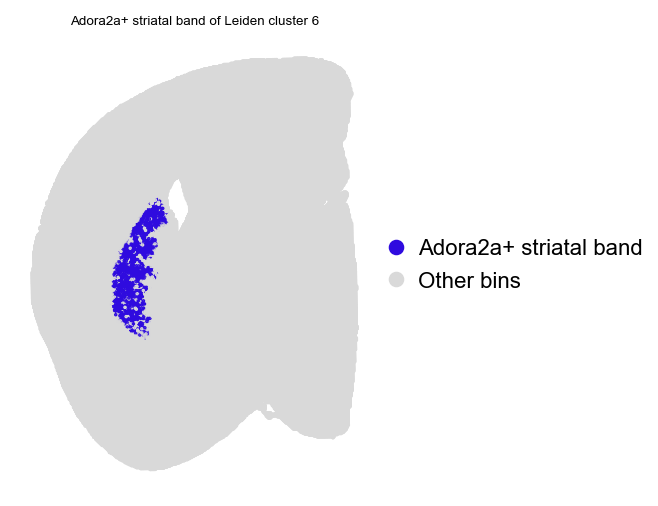

In [16]:
# 12. Extended Data Fig. 9c: the references (Lefty1+ band of Leiden cluster 7, Adora2a+ band of Leiden cluster 6) against all other bins
for region, stem, name, cluster in [
    ("Pyramidal layer", "pyramidal", "Lefty1+ pyramidal band", leiden_proxy[cell_type_1]),
    ("Striatum", "striatum", "Adora2a+ striatal band", leiden_proxy[cell_type_2]),
]:
    key = f"{stem}_reference"
    adata.obs[key] = pd.Categorical(np.where(proxies[region][1], name, "Other bins"), categories=[name, "Other bins"])
    sq.pl.spatial_scatter(
        adata,
        color=key,
        palette=ListedColormap(["#2f0bdf", "#d9d9d9"]),
        title=f"{name} of Leiden cluster {cluster}",
        save=f"ExtendedDataFig9c_{stem}_band.pdf",
        shape=None,
    )
    band_map = adata.obs[[key]].copy()
    band_map.insert(0, "y", coords[:, 1])
    band_map.insert(0, "x", coords[:, 0])
    band_map.to_csv(source_dir + f"ExtendedDataFig9c_{stem}_band.csv")

                  AUROC pyr.  AUROC str.  AUPRC pyr.  AUPRC str.  Moran's I  Geary's C
EnrichMap (null)       0.988       0.978       0.382       0.631      0.948      0.052
AUCell                 0.572       0.930       0.009       0.455      0.643      0.355
GSVA                   0.955       0.728       0.331       0.192      0.446      0.554
ssGSEA                 0.830       0.924       0.513       0.470      0.601      0.400
Z score                0.923       0.938       0.504       0.538      0.442      0.558
Scanpy                 0.901       0.917       0.431       0.493      0.376      0.624
GSDensity              0.852       0.838       0.131       0.164      0.322      0.678


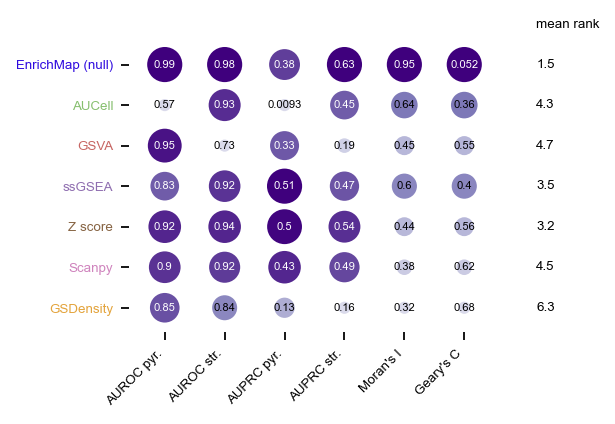

In [17]:
# 13. Extended Data Fig. 9c: benchmark summary against the region references
proxy_short = {
    "Pyramidal layer": "pyr.",
    "Striatum": "str.",
}
summary_table = pd.DataFrame(index=methods)
for key, col in [
    ("AUROC", "AUROC vs Leiden proxy"),
    ("AUPRC", "AUPRC vs Leiden proxy"),
]:
    for proxy in proxies:
        summary_table[f"{key} {proxy_short[proxy]}"] = metrics[
            metrics.region == proxy
        ].set_index("method")[col]
# spatial autocorrelation depends on the map only: one value per signature, averaged over the two signatures
mean_by_method = metrics.groupby("method")[
    ["Moran's I (6-NN)", "Geary's C (6-NN)"]
].mean()
summary_table["Moran's I"] = mean_by_method["Moran's I (6-NN)"]
summary_table["Geary's C"] = mean_by_method["Geary's C (6-NN)"]
print(summary_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(3.6, 2.6))
visiumhd_plot_summary(summary_table, ax, colours, lower_is_better=("Geary's C",))
ax.tick_params(labelsize=6)
plt.savefig(
    figure_dir + "ExtendedDataFig9c_benchmark_summary.pdf",
    bbox_inches="tight",
)
plt.show()
metrics[[
    "region", "signature", "proxy", "n region bins", "prevalence", "method", "AUROC vs Leiden proxy",
    "AUPRC vs Leiden proxy", "Moran's I (6-NN)", "Geary's C (6-NN)",
]].to_csv(source_dir + "ExtendedDataFig9c_benchmark_summary.csv", index=False)
summary_table.rename_axis("method").reset_index().to_csv(
    source_dir + "ExtendedDataFig9c_benchmark_table.csv",
    index=False,
)